In [4]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [5]:
DATASET_PATH = r"C:\Users\RAJESH DUMPALA\OneDrive\Desktop\160124748103\DL"

ZIP_PATH = os.path.join(
    DATASET_PATH,
    "HAM10000_all_images.zip"
)

CSV_PATH = os.path.join(
    DATASET_PATH,
    "HAM10000_metadata.csv"
)

IMAGE_DIR = os.path.join(
    DATASET_PATH,
    "images"
)

print("Dataset folder:", DATASET_PATH)
print("ZIP exists:", os.path.exists(ZIP_PATH))
print("CSV exists:", os.path.exists(CSV_PATH))

Dataset folder: C:\Users\RAJESH DUMPALA\OneDrive\Desktop\160124748103\DL
ZIP exists: True
CSV exists: True


In [6]:
os.makedirs(IMAGE_DIR, exist_ok=True)

# Check whether images already exist
image_count = 0

for root, folders, files in os.walk(IMAGE_DIR):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_count += 1

print("Images already present:", image_count)

if image_count < 100:
    print("Extracting ZIP...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(IMAGE_DIR)

    print("Extraction completed.")
else:
    print("Images already extracted.")

Images already present: 20030
Images already extracted.


In [7]:
image_map = {}

for root, folders, files in os.walk(IMAGE_DIR):

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_id = os.path.splitext(file)[0]

            image_map[image_id] = os.path.join(
                root,
                file
            )

print("Total images found:", len(image_map))

Total images found: 20030


In [8]:
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print(df.head())
print("\nColumns:")
print(df.columns.tolist())
df["image_path"] = df["image_id"].astype(str).map(image_map)

missing = df["image_path"].isna().sum()

print("Missing images:", missing)

df = df.dropna(
    subset=["image_path"]
).reset_index(drop=True)

print("Images available for training:", len(df))

Dataset shape: (10015, 7)
     lesion_id      image_id   dx dx_type   age   sex localization
0  HAM_0000118  ISIC_0027419  bkl   histo  80.0  male        scalp
1  HAM_0000118  ISIC_0025030  bkl   histo  80.0  male        scalp
2  HAM_0002730  ISIC_0026769  bkl   histo  80.0  male        scalp
3  HAM_0002730  ISIC_0025661  bkl   histo  80.0  male        scalp
4  HAM_0001466  ISIC_0031633  bkl   histo  75.0  male          ear

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']
Missing images: 0
Images available for training: 10015


Disease classes:
akiec : Actinic Keratoses
bcc : Basal Cell Carcinoma
bkl : Benign Keratosis
df : Dermatofibroma
mel : Melanoma
nv : Melanocytic Nevi
vasc : Vascular Lesions


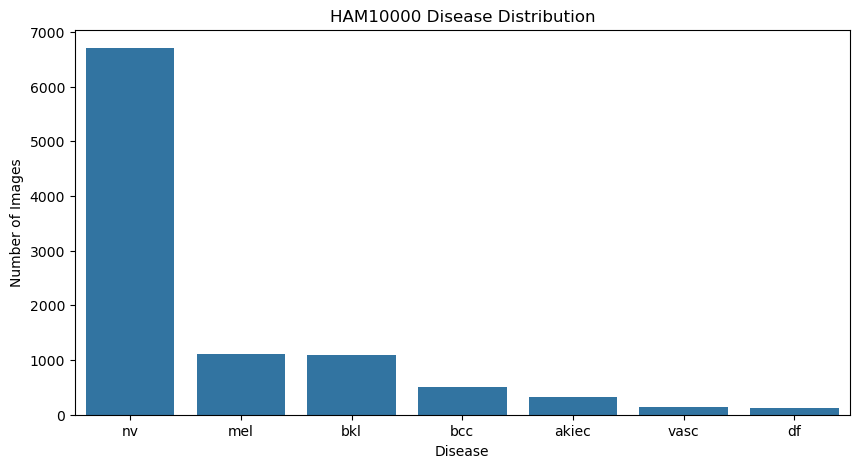

In [9]:
class_names = {
    "akiec": "Actinic Keratoses",
    "bcc": "Basal Cell Carcinoma",
    "bkl": "Benign Keratosis",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic Nevi",
    "vasc": "Vascular Lesions"
}

print("Disease classes:")

for code, name in class_names.items():
    print(code, ":", name)
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="dx",
    order=df["dx"].value_counts().index
)

plt.title("HAM10000 Disease Distribution")
plt.xlabel("Disease")
plt.ylabel("Number of Images")

plt.show()

In [10]:
classes = sorted(
    df["dx"].unique()
)

label_map = {
    label: i
    for i, label in enumerate(classes)
}

df["label"] = df["dx"].map(
    label_map
)

print("Label mapping:")
print(label_map)

print("\nExample:")
print(
    df[
        ["image_id", "dx", "label", "image_path"]
    ].head()
)

Label mapping:
{'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}

Example:
       image_id   dx  label                                         image_path
0  ISIC_0027419  bkl      2  C:\Users\RAJESH DUMPALA\OneDrive\Desktop\16012...
1  ISIC_0025030  bkl      2  C:\Users\RAJESH DUMPALA\OneDrive\Desktop\16012...
2  ISIC_0026769  bkl      2  C:\Users\RAJESH DUMPALA\OneDrive\Desktop\16012...
3  ISIC_0025661  bkl      2  C:\Users\RAJESH DUMPALA\OneDrive\Desktop\16012...
4  ISIC_0031633  bkl      2  C:\Users\RAJESH DUMPALA\OneDrive\Desktop\16012...


In [11]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

Training images: 8012
Testing images: 2003


In [12]:
def create_dataset(data, shuffle=False):

    ds = tf.data.Dataset.from_tensor_slices(
        (
            data["image_path"].values,
            data["label"].values
        )
    )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(1000)

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds


train_ds = create_dataset(
    train_df,
    shuffle=True
)

test_ds = create_dataset(
    test_df
)

print("Datasets created successfully.")

Datasets created successfully.


In [13]:
images, labels = next(
    iter(train_ds)
)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


In [14]:
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])
base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("EfficientNetB0 loaded.")

EfficientNetB0 loaded.


In [15]:
inputs = layers.Input(
    shape=(224, 224, 3)
)

x = augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(classes),
    activation="softmax"
)(x)

model = Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled.")

Model compiled.


In [18]:
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=3
)

Epoch 1/3
251/251 ━━━━━━━━━━━━━━━━━━━━ 655s 2s/step - accuracy: 0.7279 - loss: 0.7357 - val_accuracy: 0.7299 - val_loss: 0.7261
Epoch 2/3
251/251 ━━━━━━━━━━━━━━━━━━━━ 459s 2s/step - accuracy: 0.7376 - loss: 0.7112 - val_accuracy: 0.7414 - val_loss: 0.7022
Epoch 3/3
251/251 ━━━━━━━━━━━━━━━━━━━━ 473s 2s/step - accuracy: 0.7450 - loss: 0.6926 - val_accuracy: 0.7469 - val_loss: 0.6870


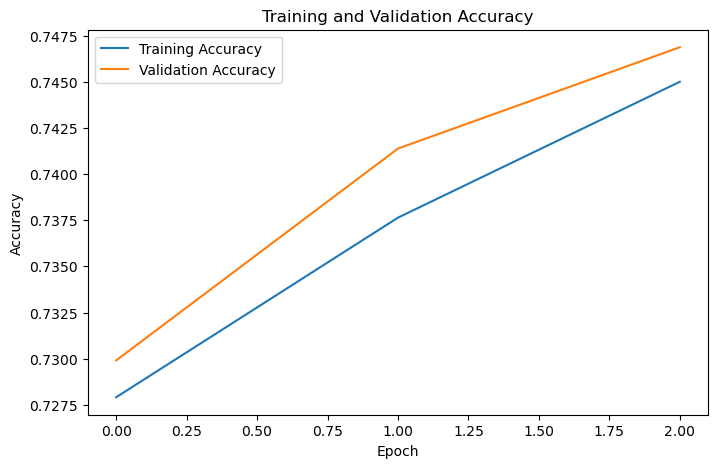

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.show()

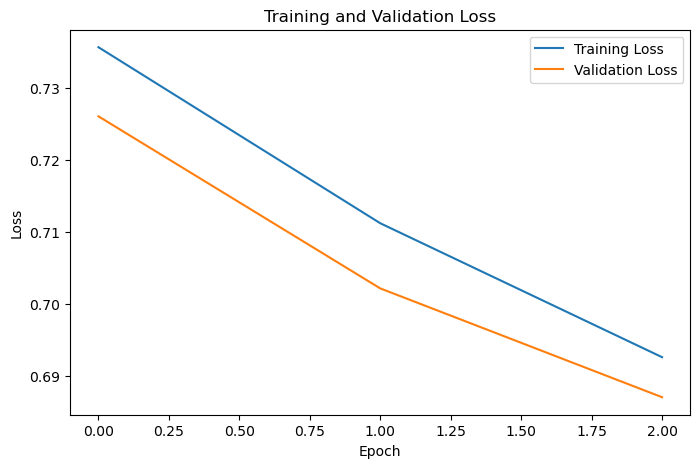

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.show()

In [21]:
test_loss, test_accuracy = model.evaluate(
    test_ds
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print(
    f"Test Accuracy: {test_accuracy * 100:.2f}%"
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.7469 - loss: 0.6870
Test Loss: 0.6870481371879578
Test Accuracy: 0.7468796968460083
Test Accuracy: 74.69%


In [23]:
predictions = model.predict(
    test_ds
)

y_pred = np.argmax(
    predictions,
    axis=1
)

y_true = test_df["label"].values

print("Predictions generated.")

63/63 ━━━━━━━━━━━━━━━━━━━━ 96s 2s/step
Predictions generated.


In [24]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            class_names[c]
            for c in classes
        ]
    )
)

                      precision    recall  f1-score   support

   Actinic Keratoses       0.85      0.17      0.28        65
Basal Cell Carcinoma       0.56      0.28      0.37       103
    Benign Keratosis       0.55      0.42      0.48       220
      Dermatofibroma       0.00      0.00      0.00        23
            Melanoma       0.41      0.37      0.39       223
    Melanocytic Nevi       0.81      0.95      0.88      1341
    Vascular Lesions       0.85      0.39      0.54        28

            accuracy                           0.75      2003
           macro avg       0.58      0.37      0.42      2003
        weighted avg       0.72      0.75      0.72      2003



C:\Users\RAJESH DUMPALA\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\RAJESH DUMPALA\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\RAJESH DUMPALA\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


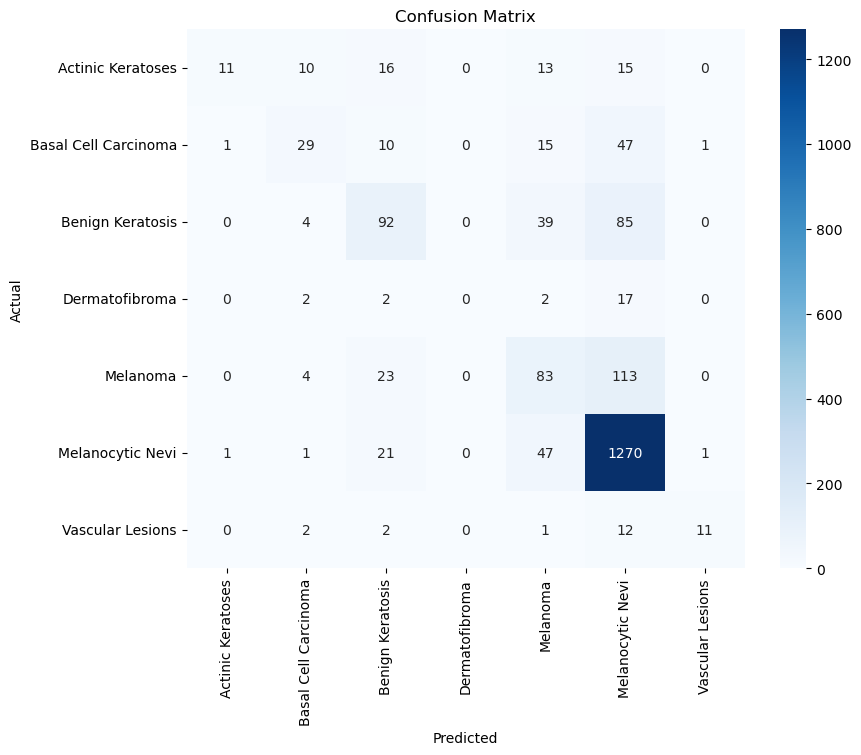

In [25]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        class_names[c]
        for c in classes
    ],
    yticklabels=[
        class_names[c]
        for c in classes
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [26]:
MODEL_PATH = os.path.join(
    DATASET_PATH,
    "skin_disease_model.keras"
)

model.save(
    MODEL_PATH
)

print("Model saved successfully:")
print(MODEL_PATH)



Model saved successfully:
C:\Users\RAJESH DUMPALA\OneDrive\Desktop\160124748103\DL\skin_disease_model.keras


In [27]:
# Select a random existing image
random_row = df.sample(
    1
).iloc[0]

TEST_IMAGE = random_row["image_path"]

actual_code = random_row["dx"]

actual_disease = class_names[
    actual_code
]

print("Selected image:")
print(os.path.basename(TEST_IMAGE))

print("\nFull path:")
print(TEST_IMAGE)

print("\nActual disease:")
print(actual_disease)

Selected image:
ISIC_0032548.jpg

Full path:
C:\Users\RAJESH DUMPALA\OneDrive\Desktop\160124748103\DL\images\HAM10000_all_images\ISIC_0032548.jpg

Actual disease:
Melanocytic Nevi


In [28]:
img = tf.keras.utils.load_img(
    TEST_IMAGE,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(
    img
)

img_array = np.expand_dims(
    img_array,
    axis=0
)

prediction = model.predict(
    img_array,
    verbose=0
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_code = classes[
    predicted_index
]

predicted_disease = class_names[
    predicted_code
]

confidence = (
    prediction[0][predicted_index] * 100
)

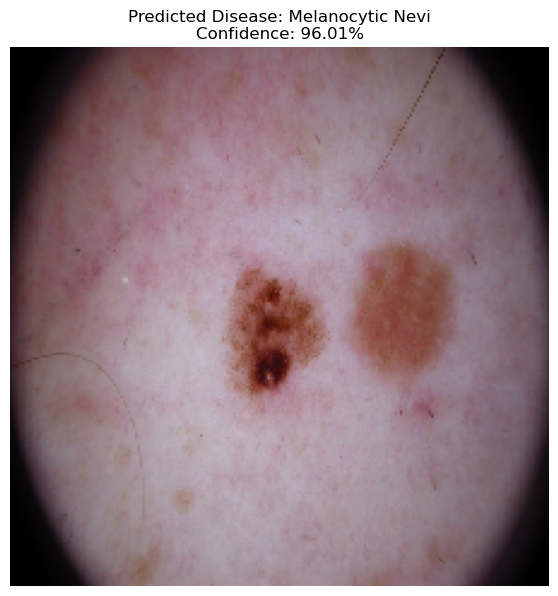


       SKIN DISEASE PREDICTION
Image           : ISIC_0032548.jpg
Actual Disease  : Melanocytic Nevi
Predicted Disease: Melanocytic Nevi
Confidence      : 96.01%


In [29]:
plt.figure(figsize=(7, 7))

plt.imshow(img)

plt.axis("off")

plt.title(
    f"Predicted Disease: {predicted_disease}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.show()

print("\n====================================")
print("       SKIN DISEASE PREDICTION")
print("====================================")
print(
    "Image           :",
    os.path.basename(TEST_IMAGE)
)
print(
    "Actual Disease  :",

    actual_disease
)
print(
    "Predicted Disease:",
    predicted_disease
)
print(
    f"Confidence      : {confidence:.2f}%"
)
print("====================================")